# Clustering Made Simple: K-Means and DBSCAN

**Audience:** Beginners with little or no coding background
**Dataset:** The exact same mall-customer dataset is used for both models, so you can compare them fairly.

## What you will learn
- What clustering means, in plain language
- How a computer decides which data points are "similar"
- How K-Means learns, step by step
- How DBSCAN learns, step by step
- The key knobs (parameters) of each model and what they do
- How to read - and question - the groups a model creates
- Where each model is used in the real world

> This notebook keeps the **code very short on purpose**. Most of the learning happens in the text (theory) cells above each piece of code - read them before running the code below.

## 1. What is clustering?

Imagine you are handed a box of mixed buttons - different colors, sizes, and shapes - and asked to **sort them into groups**. Nobody tells you how many groups to make, or what to call them. You would naturally put similar-looking buttons together. That is exactly what **clustering** does with data.

**Clustering** is a type of **unsupervised machine learning**:
- *Unsupervised* means the data has **no "correct answer" column**. Nobody has already written down the right group for each row.
- The computer only sees **numbers** (like income and spending score) and groups the rows that are **close to each other**.
- A "cluster" is simply a group of rows the algorithm believes belong together.

### How does a computer decide "closeness"?
Every customer in our data is really just **two numbers**: income and spending score. We can picture each customer as a **dot on a graph**, where the x-axis is income and the y-axis is spending score. Two dots that sit near each other on the graph are considered "similar"; two dots far apart are considered "different". This "nearness on the graph" is called **distance**, and it is the heart of almost every clustering algorithm.

You never need to calculate distance by hand - the scikit-learn library does it internally. Just remember: **smaller distance = more similar**.

### Clustering is not classification
| | Classification | Clustering |
|---|---|---|
| Answer labels given during training? | Yes | No |
| Goal | Predict a known label (e.g., "spam" or "not spam") | Discover unknown groups |
| Example question | "Is this email spam?" | "Which customers behave similarly?" |

### Everyday examples of clustering
- Grouping shoppers by income and spending habits (what we do in this notebook)
- Finding busy delivery zones in a city
- Grouping similar news articles or songs
- Spotting unusual banking transactions
- Compressing an image by grouping similar colors together

> **Important:** A cluster is only a mathematical grouping. A human should always check whether the resulting groups actually make sense - and are used responsibly.

In [1]:
# Import the tools used in this lesson (run this cell first)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42  # keeps our "random" results identical every time we run this
sns.set_theme(style="whitegrid")
print("Libraries ready.")

Libraries ready.


## 2. Meet the mall-customer dataset

To keep this notebook simple and reliable (no internet download needed), we generate a realistic **practice dataset** that behaves like real mall-customer data: customers with naturally different shopping habits, plus a handful of unusual customers.

| Column | Plain-language meaning |
|---|---|
| CustomerID | A unique number for each customer |
| Annual Income (k$) | Yearly income, in thousands of dollars |
| Spending Score (1-100) | A score the mall gives based on how actively a customer spends; higher = spends more |

### Why cluster using Income and Spending Score?
These two numbers together answer a very practical business question:
> *"Which customers earn and spend in similar ways, so I can market to them as one group?"*

A customer with **high income but low spending** needs a different marketing message than a customer with **low income but high spending**. Clustering helps a business discover these natural groups automatically, instead of guessing.

### How the practice data is built
We use a scikit-learn helper called `make_blobs`, which creates several "blobs" (clouds) of points around different centers - this mimics natural customer groups forming on their own. We then stretch and shift the numbers so they look like realistic income and spending values, and add a few unusual customers by hand so we can later see how DBSCAN treats them as **noise**.

In [2]:
# 5 natural customer groups, plus 5 unusual ("outlier") customers
centers = np.array([[-8, -8], [-8, 8], [8, -8], [8, 8], [0, 0]])
blob_points, _ = make_blobs(n_samples=280, centers=centers, cluster_std=1.2, random_state=RANDOM_STATE)
outliers = np.array([[-13, 13], [13, -13], [0, 14], [14, 0], [-13, -13]])
raw_points = np.vstack([blob_points, outliers])

df_mall = pd.DataFrame({
    "CustomerID": range(1, len(raw_points) + 1),
    "Annual Income (k$)": np.clip(raw_points[:, 0] * 4.3 + 62, 8, 128).round(1),
    "Spending Score (1-100)": np.clip(raw_points[:, 1] * 3.8 + 50, 2, 98).round(1),
})
df_mall.head()

,CustomerID,Annual Income (k$),Spending Score (1-100)
0,1,24.1,81.5
1,2,27.0,18.2
2,3,32.3,21.1
3,4,95.8,82.2
4,5,53.4,52.5


Rows: 285


,CustomerID,Annual Income (k$),Spending Score (1-100)
count,285.0,285.0,285.0
mean,143.0,62.0,49.9
std,82.4,32.0,28.3
min,1.0,8.0,2.0
25%,72.0,28.8,20.8
50%,143.0,61.4,48.9
75%,214.0,95.3,79.4
max,285.0,122.2,98.0


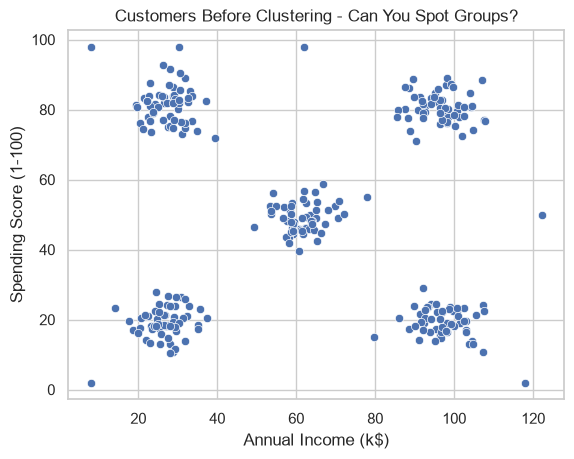

In [3]:
# A quick look before modeling
print("Rows:", df_mall.shape[0])
display(df_mall.describe().round(1))

sns.scatterplot(data=df_mall, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Customers Before Clustering - Can You Spot Groups?")
plt.show()

## 3. Why we scale the data before clustering

Both K-Means and DBSCAN decide "closeness" using distance. If one column has much bigger numbers than another, it will unfairly dominate the distance calculation.

**Analogy:** Comparing "5 kilograms" with "5 kilometers" side by side does not make sense - they are on completely different scales. Here, income (values like 10-130) and spending score (values like 1-100) happen to be on similar scales, but in general, clustering features can have very different ranges (for example, income in dollars versus age in years). Scaling is a **best practice you should always apply**, so we do it here too.

`StandardScaler` converts every column so that it has:
- a mean (average) of 0
- a standard deviation (spread) of 1

This puts every feature on the same "measuring stick" before distances are calculated.

In [4]:
# Scale the two features so they are equally weighted in distance calculations
features = df_mall[["Annual Income (k$)", "Spending Score (1-100)"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Part A: K-Means Clustering

## 4. What is K-Means?

K-Means splits all customers into a fixed number of groups, called **K**. Each group has an imaginary center point called a **centroid** - think of it as the "average customer" of that group.

### Step-by-step: how K-Means learns
Think of K-Means like organizing people into K meeting points at a large park:

1. **Choose K.** You decide how many groups you want (say, K = 5).
2. **Drop K pins on the map.** The algorithm places K starting centroids (this can be smarter than random - see `init` below).
3. **Everyone walks to the nearest pin.** Every customer is assigned to whichever centroid is closest to them (using distance).
4. **Each pin moves to the average position** of everyone who walked to it - like the group deciding on a fairer meeting spot.
5. **Repeat steps 3 and 4.** People may switch groups as pins move, until the pins stop moving much (the model has *converged*).

This is why K-Means is sometimes summarized as "guess, assign, average, repeat".

### Important parameters
| Parameter | Plain-language meaning | Beginner tip |
|---|---|---|
| `n_clusters` (K) | How many groups to create | Try a few values and compare (see next section) |
| `init` | How the starting centroids are placed | `"k-means++"` is a smart default that spreads them out |
| `n_init` | How many times to retry with different starting points | 10 or more avoids an unlucky start |
| `max_iter` | Maximum number of "assign then move" rounds | The default is almost always enough |
| `random_state` | A fixed seed so results are reproducible | Use any fixed number while learning |

### Strengths and limitations
- Fast, simple, and easy to explain to non-technical people - it literally produces a "center" for each group.
- Works very well when groups are roughly round and similarly sized.
- You must decide K in advance.
- Every point is forced into a group - even a very unusual customer will be pulled into the nearest cluster. K-Means has no concept of "noise".

## 5. How do we choose K?

There is no single "correct" K, but two common tools help us make an informed guess:

- **Inertia (used in the "elbow method"):** the total distance between each point and its own centroid. It always gets smaller as K increases, so we look for the **"elbow"**: the point where adding more groups stops giving a big improvement. Imagine a hiking trail that drops steeply, then suddenly flattens out - that flattening point is the elbow.
- **Silhouette score:** for each point, this compares "how close it is to its own group" against "how close it is to the nearest other group". The score ranges from **-1 (badly grouped)** to **+1 (perfectly grouped)**, and higher is better.

In the code below we calculate the **silhouette score** for K = 2 through 8 and plot it, so we can pick the K with the highest score.

> A score is only a guide. The final choice of K should also make business sense.

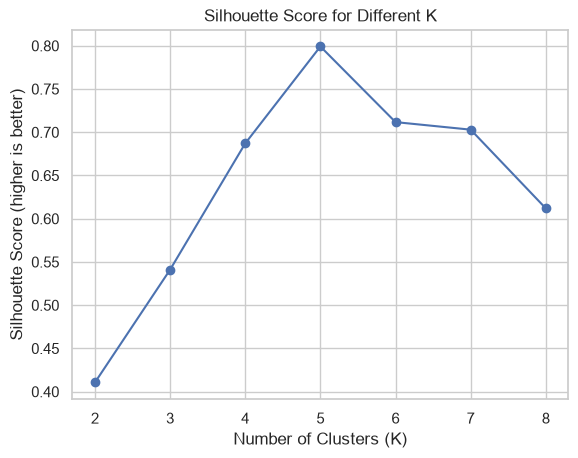

In [5]:
# Try several values of K and score each one
k_values = range(2, 9)
silhouette_scores = []
for k in k_values:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score for Different K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score (higher is better)")
plt.show()

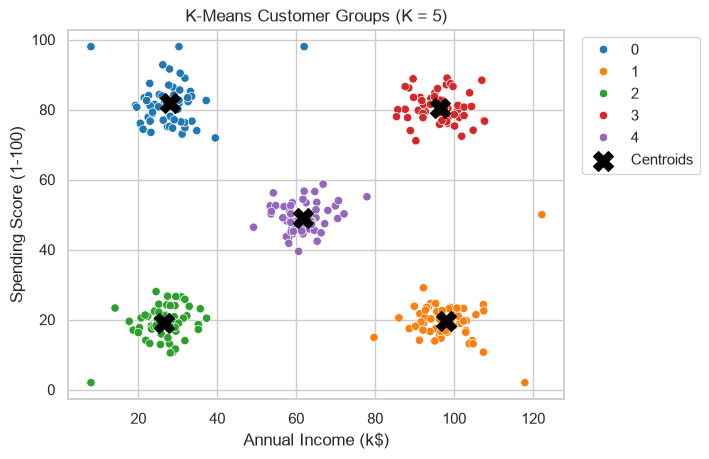

In [6]:
# The scores above point to K = 5 - train the final K-Means model
kmeans = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
df_mall["KMeans Group"] = kmeans.fit_predict(X_scaled)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

sns.scatterplot(data=df_mall, x="Annual Income (k$)", y="Spending Score (1-100)", hue="KMeans Group", palette="tab10")
plt.scatter(centroids[:, 0], centroids[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.title("K-Means Customer Groups (K = 5)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 6. Reading the K-Means groups

The numbers 0, 1, 2, 3, 4 next to each group are just **labels**, similar to naming teams "Team 0" and "Team 1" - they carry **no ranking**. Group 3 is not "better" than Group 0, and the numbers can even change if you re-run the model.

The safest way to understand a cluster is to look at its **average income and average spending score**, and describe it in plain English. The table below does exactly that.

Typical group descriptions you might recognize:
- High income + high spending -> **premium shoppers**, worth rewarding with loyalty perks
- High income + low spending -> **cautious spenders**, perhaps open to premium value offers
- Low income + high spending -> **enthusiastic budget shoppers**, good for small, frequent promotions
- Low income + low spending -> **low-engagement customers**, may need a different marketing channel
- Middle income + middle spending -> **average, typical customers**

Match these plain-language descriptions to the actual average numbers in your table - don't just guess from the cluster number.

In [7]:
# Average income and spending score per group - the safest way to interpret clusters
df_mall.groupby("KMeans Group")[["Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)

,Annual Income (k$),Spending Score (1-100)
KMeans Group,,
0,27.9,81.9
1,97.9,19.7
2,26.5,18.9
3,96.4,80.6
4,61.6,49.0


## 7. Try it yourself: interactive K-Means

Use the slider below to change K and watch the groups change live. Ask yourself:
- Does a small K merge groups that look different on the chart?
- Does a large K split one natural group into two unnecessarily?

(If interactive sliders are not available in your setup, a single static example is shown instead.)

In [8]:
def show_kmeans(k=5):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    plt.scatter(features.iloc[:, 0], features.iloc[:, 1], c=labels, cmap="tab10")
    plt.title(f"K-Means with K = {k}")
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score (1-100)")
    plt.show()

try:
    from ipywidgets import interact
    interact(show_kmeans, k=(2, 8))
except ImportError:
    print("Interactive widgets are unavailable - showing a static K = 5 example.")
    show_kmeans()

interactive(children=(IntSlider(value=5, description='k', max=8, min=2), Output()), _dom_classes=('widget-inte…

# Part B: DBSCAN Clustering

## 8. What is DBSCAN?

**DBSCAN** stands for **Density-Based Spatial Clustering of Applications with Noise**. Instead of asking "how many groups do you want?", it asks **"where are the crowded areas?"**

**Analogy:** Picture a music festival from above. Dense crowds form near popular stages - these groups are naturally visible, with no need to count them in advance. A person standing alone, far from any stage, is not really part of any crowd - DBSCAN calls this person **noise**.

### Three kinds of points
- **Core point** - has enough neighbors close by (a busy spot).
- **Border point** - is close to a core point, but does not have enough neighbors of its own to be a core point (the edge of the crowd).
- **Noise point** - is not close to any dense group at all (the lonely person). Scikit-learn labels noise points as **-1**.

### Step-by-step: how DBSCAN learns
1. Pick an unvisited customer.
2. Look inside a circle of radius `eps` around them and count the neighbors.
3. If there are at least `min_samples` neighbors, this is a **core point** - start (or grow) a cluster here.
4. Keep expanding the cluster through every connected core point's neighborhood.
5. Any customer never reached by a dense neighborhood is labeled **noise (-1)**.

### Important parameters
| Parameter | Plain-language meaning | Effect of changing it |
|---|---|---|
| `eps` | The radius of the "neighborhood circle" | Too small -> lots of noise; too large -> groups merge into one |
| `min_samples` | Minimum neighbors needed to call a spot "crowded" | A larger value demands denser groups |
| `metric` | The way distance is measured | `"euclidean"` (straight-line distance) is the common default |

### Strengths and limitations
- You do **not** need to know the number of groups in advance.
- Can find oddly-shaped groups, not just round ones.
- Naturally identifies unusual points as noise - very useful for outlier spotting.
- Struggles when real groups have very different densities (crowded versus spread-out).
- Choosing good `eps` and `min_samples` can take some trial and error.

## 9. Choosing `eps`: the k-distance plot

A common trick: for every point, measure the distance to its `min_samples`-th nearest neighbor, then sort all these distances from smallest to largest and plot them. Most points will have a small, similar distance (they're inside crowds) until the line suddenly bends upward - that bend is a good starting guess for `eps`.

This is a **guide, not a guarantee** - you may still need to try a couple of nearby values.

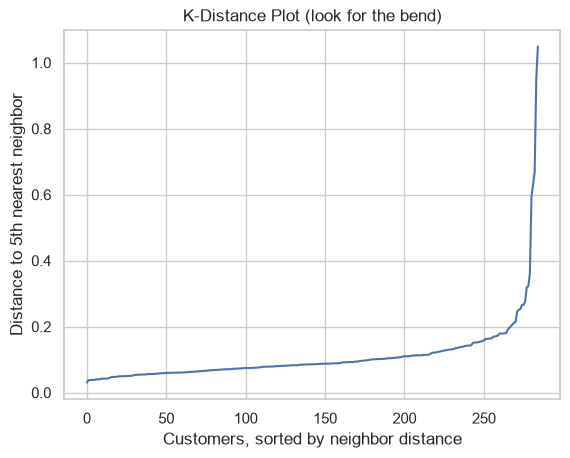

In [9]:
# Distance from each point to its 5th nearest neighbor, sorted smallest to largest
distances, _ = NearestNeighbors(n_neighbors=5).fit(X_scaled).kneighbors(X_scaled)
plt.plot(np.sort(distances[:, -1]))
plt.title("K-Distance Plot (look for the bend)")
plt.xlabel("Customers, sorted by neighbor distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.show()

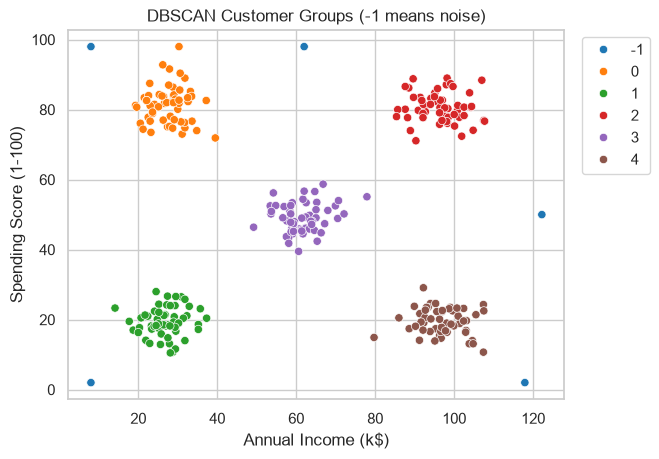

DBSCAN Group
 0    56
 1    56
 2    56
 3    56
 4    56
-1     5
Name: Customers, dtype: int64

In [10]:
# Fit DBSCAN using the bend spotted above as our eps guess
dbscan = DBSCAN(eps=0.3, min_samples=5)
df_mall["DBSCAN Group"] = dbscan.fit_predict(X_scaled)

sns.scatterplot(data=df_mall, x="Annual Income (k$)", y="Spending Score (1-100)", hue="DBSCAN Group", palette="tab10")
plt.title("DBSCAN Customer Groups (-1 means noise)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

df_mall["DBSCAN Group"].value_counts().rename("Customers")

## 10. Try it yourself: interactive DBSCAN

Move the sliders below and notice:
- Lower `eps` -> smaller neighborhoods -> usually **more noise**.
- Higher `eps` -> larger neighborhoods -> groups may **merge together**.
- Higher `min_samples` -> the model demands denser groups before calling something a cluster.

> If everything becomes one giant cluster, or almost everything becomes noise, the parameters need adjusting.

In [11]:
def show_dbscan(eps=0.3, min_samples=5):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    plt.scatter(features.iloc[:, 0], features.iloc[:, 1], c=labels, cmap="tab10")
    plt.title(f"DBSCAN - eps={eps}, min_samples={min_samples}")
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score (1-100)")
    plt.show()

try:
    from ipywidgets import interact
    interact(show_dbscan, eps=(0.1, 0.8, 0.05), min_samples=(3, 15))
except ImportError:
    print("Interactive widgets are unavailable - showing a static example.")
    show_dbscan()

interactive(children=(FloatSlider(value=0.3, description='eps', max=0.8, min=0.1, step=0.05), IntSlider(value=…

# Part C: Compare the Models

| Question | K-Means | DBSCAN |
|---|---|---|
| Must choose the number of clusters first? | Yes, choose K | No |
| Main idea | Distance to moving centers | Connected dense neighborhoods |
| Cluster shape | Best for compact, round groups | Can find irregular shapes |
| Handles noise directly? | No, every point gets a cluster | Yes, noise is labeled -1 |
| Sensitive to | Starting centers, K, scale, outliers | `eps`, `min_samples`, scale, changing density |
| Has centroids? | Yes | No |
| Predicting a group for a brand-new customer | Straightforward | Not built in by default |

## Practical choice
- Start with **K-Means** when you expect compact groups, need exactly K segments, and want easy-to-explain centers.
- Try **DBSCAN** when noise matters, cluster shapes may be irregular, and you do not know the number of groups in advance.
- It is common to test more than one method. Scores, plots, domain knowledge, and business usefulness all matter together.

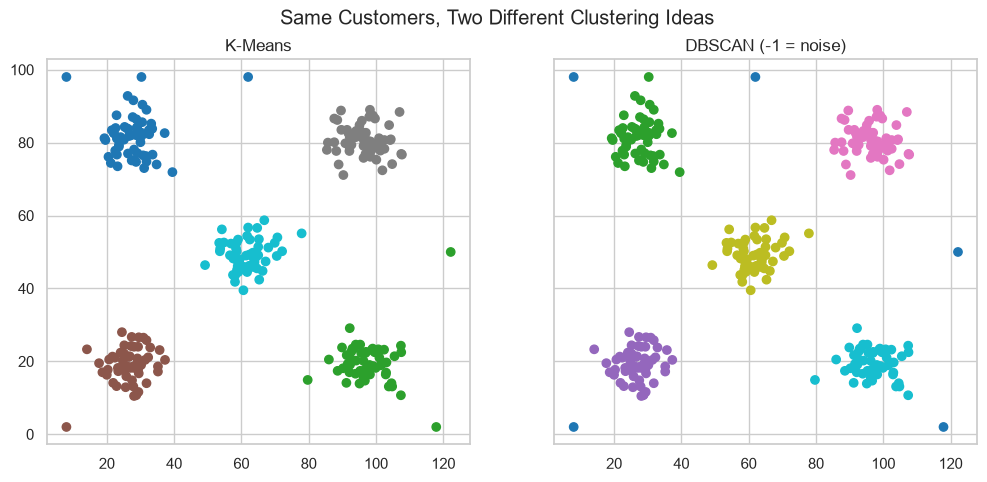

K-Means groups: 5
DBSCAN groups (excluding noise): 5
DBSCAN noise points: 5


In [12]:
# Put both results side by side on the same customers
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(features.iloc[:, 0], features.iloc[:, 1], c=df_mall["KMeans Group"], cmap="tab10")
axes[0].set_title("K-Means")
axes[1].scatter(features.iloc[:, 0], features.iloc[:, 1], c=df_mall["DBSCAN Group"], cmap="tab10")
axes[1].set_title("DBSCAN (-1 = noise)")
plt.suptitle("Same Customers, Two Different Clustering Ideas")
plt.show()

print("K-Means groups:", df_mall["KMeans Group"].nunique())
print("DBSCAN groups (excluding noise):", df_mall.loc[df_mall["DBSCAN Group"] != -1, "DBSCAN Group"].nunique())
print("DBSCAN noise points:", int((df_mall["DBSCAN Group"] == -1).sum()))

## 11. Real-world uses

### K-Means examples
- **Customer segmentation:** create a chosen number of marketing groups.
- **Image compression:** replace many similar colors with a smaller set of centroid colors.
- **Store grouping:** group branches with similar sales patterns.
- **Document grouping:** organize articles into broad themes after text is converted into numbers.

### DBSCAN examples
- **Delivery hotspots:** discover dense order locations and isolated addresses.
- **Geospatial analysis:** find dense GPS activity without choosing the number of areas first.
- **Fraud or anomaly exploration:** flag isolated behavior as noise for human review.
- **Sensor analysis:** separate normal, dense operating regions from unusual readings.

> Noise is not proof of fraud, and a cluster is not proof that all its members behave identically. These outputs support human decisions - they should not replace careful review.

## 12. Common beginner mistakes

1. **Not scaling distance-based features.** One large-scale feature may quietly control the entire result.
2. **Choosing K only from one score.** Also check the plots, stability, and whether the groups make business sense.
3. **Assuming cluster labels have rank.** Label 3 is not "better" than label 1.
4. **Treating DBSCAN's label -1 as an error.** It intentionally means "noise", not a bug.
5. **Using raw latitude and longitude carelessly.** Real geographic distance may need special handling.
6. **Calling every unusual point "fraud".** An anomaly is a clue for a human to review, not a verdict.
7. **Forgetting that results can change.** Different data, features, scaling, or parameters all change the clusters.
8. **Using sensitive attributes without review.** Customer grouping can create unfair outcomes if used carelessly.

## 13. Quick knowledge check

Try answering before opening the answers below.

1. Why is clustering called unsupervised learning?
2. What does K represent in K-Means?
3. Why do we scale income and spending score before clustering?
4. What does DBSCAN's label -1 mean?
5. What usually happens when `eps` becomes too small?
6. Which model is forced to assign every customer to a cluster, even unusual ones?

<details>
<summary><b>Click to show answers</b></summary>

1. The training data has no correct group label supplied to the model - the model discovers groups on its own.
2. K is the number of clusters (groups) you ask the model to create.
3. Scaling gives every feature a comparable influence on the distance calculation.
4. It means the point is considered noise, not a regular member of any cluster.
5. Neighborhoods shrink, clusters may break apart, and noise usually increases.
6. K-Means.
</details>

## 14. Practice exercises

### Beginner
1. Change K from 5 to 4 in the K-Means code. Which two customer groups combine into one?
2. Change DBSCAN's `eps` to 0.2 and then to 0.5. Record how the cluster count and noise count change.
3. Filter `df_mall` to show only the rows where `DBSCAN Group` is -1.

### Intermediate
4. Add `Age` as a column (you can generate it with `np.random.randint`) and cluster on all three features.
5. Re-run K-Means with a different `random_state`. Does the group summary table stay roughly the same?
6. Try `min_samples=3` and `min_samples=10` in DBSCAN. Which one finds more noise?

### Discussion
7. A marketing team insists on exactly four customer segments. Which model fits that requirement more directly, and why?
8. A delivery company wants to find busy order zones and flag isolated addresses. Which model would you try first?

## Final recap
- Clustering discovers groups without any known answers.
- K-Means uses K moving centroids and forces every point into a group.
- DBSCAN grows dense neighborhoods and can label unusual points as noise (-1).
- Scaling matters because both methods rely on distance.
- Parameters strongly shape the result - always sanity-check with a plot.
- The best clustering result is not just visually neat; it must also be stable, understandable, responsible, and useful for a real decision.